# Projeto 01 - Agente de Rotas para Comida Local (IA 2026-27)

*Inteligência Artificial - Licenciatura em Engenharia de Sistemas Informáticos (UPCA / EST)*

### Equipa (Grupo G04)
| Nome | Número |
|------|--------|
| Diogo Apolinário | 6731 |
| Raúl Ribeiro | 22552 |
| Miguel Correia | 31028 |
| José Ferreira | 31556 |

**Repositório GitHub:** https://github.com/JoseFerreira31556/IA26_P01_G04.git

### Organização do projeto
- **`01_eda_tiny.ipynb`**: contexto do projeto, análise exploratória dos dados (EDA);
- **`test_handwritten_routes`**: testes com rotas escritas à mão;
- **`model.py`**: modelo do problema (classes, leitura dos dados, função de custo, verificador de rotas);
- **`02_problem_solving.ipynb`** (este notebook): resolução do problema, análise de resultados e conclusão.

## Resolução do problema: pesquisa informada, pesquisa local e CSP

Este notebook usa o módulo `model.py` (classes `Problem`, `Request`, `Vehicle` e `State`, função de custo `routeCost`/`solutionCost`, verificador `checkRoute` e tradutora `buildCheckData`) para resolver o problema de recolha e entrega com três famílias de algoritmos:

1. **Pesquisa informada:** Greedy best-first e A\*, cada uma com 2 heurísticas;
2. **Pesquisa local:** Hill-Climbing a partir da solução do Greedy;
3. **CSP:** formulação com variáveis, domínios e restrições, resolvida por backtracking.

Os algoritmos foram adaptados dos notebooks das aulas (`greedy_search`, `a_star_salesman`, `hill_climbing`). Nesses moldes, a geração de movimentos estava escrita para cada problema (puzzle de 8 peças, mapa da Roménia, 8 rainhas); aqui foi substituída por funções do nosso modelo.

---
## 0. Preparação

Carregamos os dados com as funções do `model.py` e preparamos o dicionário usado pelo verificador. Todas as rotas encontradas pelos algoritmos são validadas no fim com o `checkRoute`.

In [1]:
# Libraries
import os
import time
import heapq
import pandas as pd
import matplotlib.pyplot as plt

import model

# Load the data and create the Problem
path = "./data/data_tiny_20261020/"
data = model.read_csv_files(path, sorted(os.listdir(path)))
problem = model.loadProblem(data)
checkData = model.buildCheckData(problem)

# Values used by all algorithms
T0 = pd.Timestamp(problem.rules["start_date"])   # start of the planning horizon (minute 0)
SERVICE = checkData["service"]                    # service time at each pickup / delivery stop
HANDLING = checkData["handling"]                  # time to unload / load at the warehouse
DEPOT = problem.vehicles[0].depotStopId           # stop of the warehouse

requestById = {r.orderItemId: r for r in problem.requests}
stopName = dict(zip(problem.locations["location_id"], problem.locations["name"]))


def travel(a, b):
    # Travel time between two stops (0 when it is the same stop)
    if a == b:
        return pd.Timedelta(0)
    return checkData["travel"][(a, b)]


print("Requests (items):", len(problem.requests), "| Vehicles:", len(problem.vehicles), "| Warehouse: stop", DEPOT)

Requests (items): 40 | Vehicles: 2 | Warehouse: stop 4


### 0.1 Divisão das encomendas pelos veículos

O `State` do modelo representa **um veículo**. Por isso, seguimos a abordagem clássica *cluster-first, route-second*:

1. **Agrupar:** cada encomenda é atribuída a um veículo pela localização do local de entrega. As que ficam a **oeste** do armazém (Esposende e Famalicão) vão para o veículo 1; as que ficam a **este** (Guimarães) vão para o veículo 2.
2. **Planear:** cada veículo faz as recolhas e as entregas das suas encomendas, e a rota de cada um é procurada separadamente.

Cada encomenda fica inteira num veículo, que recolhe todos os seus itens nos produtores e a entrega completa. Confirmamos que a carga de cada veículo cabe na sua capacidade.

In [2]:
def assignOrders(problem):
    # Orders delivered west of the warehouse -> vehicle 1, east -> vehicle 2
    depotLon = problem.locations.loc[problem.locations["location_id"] == DEPOT, "longitude"].iloc[0]
    lonOfStop = dict(zip(problem.locations["location_id"], problem.locations["longitude"]))
    assignment = {}
    for r in problem.requests:
        if lonOfStop[r.deliveryStopId] < depotLon:
            assignment[r.orderId] = problem.vehicles[0].vehicleId
        else:
            assignment[r.orderId] = problem.vehicles[1].vehicleId
    return assignment


assignment = assignOrders(problem)

for v in problem.vehicles:
    vOrders = sorted({o for o, vv in assignment.items() if vv == v.vehicleId})
    weight = sum(r.weightKg for r in problem.requests if assignment[r.orderId] == v.vehicleId)
    print(f"Vehicle {v.vehicleId}: orders {vOrders} | {weight:.1f} kg of {v.capacityKg:.0f} kg")

Vehicle 1: orders [2, 3, 8, 10, 12] | 107.5 kg of 150 kg
Vehicle 2: orders [1, 4, 5, 6, 7, 9, 11] | 162.5 kg of 200 kg


---
## 1. Pesquisa informada (Greedy e A\*)

### 1.1 Formulação

- **Estado (`model.State`):** paragem atual do veículo, hora atual, carga, e os itens em cada fase: por recolher (`pendingRequests`), recolhidos e a caminho do armazém (`pickedRequests`), já passados pelo armazém e prontos a entregar (`warehouseRequests`) e entregues (`deliveredRequests`).
- **Estado inicial:** o veículo no armazém, no início do horizonte, com todos os itens das suas encomendas por recolher.
- **Ações:**
  - **recolher** num produtor: o veículo viaja até lá e recolhe os itens cuja janela de disponibilidade contém a hora de início do serviço. Pode começar à chegada ou esperar até abrir a janela de outro item, e cada opção dá um sucessor diferente;
  - **ir ao armazém:** descarrega o que veio dos produtores e volta a carregar esses itens para entrega (2 × 15 min de manuseamento). Cumpre a regra `flow` (todos os produtos passam pelo armazém);
  - **entregar** uma encomenda completa, se todos os seus itens já passaram pelo armazém, dentro da janela de entrega (se chegar cedo, espera);
  - **regressar** ao armazém, quando já não há nada por fazer.
- **Teste de objetivo:** todos os itens entregues e o veículo de volta ao armazém.
- **Custo de cada passo:** a distância em km entre as duas paragens (`problem.distance`), a mesma que a função de custo `routeCost` soma.
- **Poda:** um estado em que um item por recolher já perdeu a janela de recolha, ou um item por entregar já perdeu a janela de entrega, é descartado, porque nunca chega ao objetivo.

**Simplificação:** os itens são carregados logo a seguir a serem descarregados no armazém, por isso o limite de 24 h no armazém (`max_warehouse_dwell_h`) é sempre cumprido.

In [3]:
def initialState(vehicle):
    items = [r.orderItemId for r in problem.requests if assignment[r.orderId] == vehicle.vehicleId]
    return model.State(vehicle.vehicleId, vehicle.depotStopId, T0, 0.0, items, [], [], [])


def isGoal(state):
    # Everything delivered and the vehicle is back at the warehouse
    return (len(state.pendingRequests) == 0 and len(state.pickedRequests) == 0
            and len(state.warehouseRequests) == 0 and state.locationId == DEPOT)


def isDeadEnd(state):
    # A pending item whose pickup window already closed, or an undelivered item whose delivery window closed
    for i in state.pendingRequests:
        if state.currentTime > requestById[i].availabilityEnd:
            return True
    for i in state.pendingRequests | state.pickedRequests | state.warehouseRequests:
        if state.currentTime > requestById[i].deliveryEnd:
            return True
    return False


def successors(state, vehicle):
    # Returns a list of (action, next state, step cost in km)
    # action = (type, stop, items, time when the service ends)
    result = []
    here = state.locationId

    # 1) Pick up items at a producer
    producers = {requestById[i].pickupStopId for i in state.pendingRequests}
    for p in producers:
        arrival = state.currentTime + travel(here, p)
        candidates = [i for i in state.pendingRequests if requestById[i].pickupStopId == p]
        # Possible service start times: on arrival, or waiting until the window of another item opens
        starts = {arrival}
        for i in candidates:
            if requestById[i].availabilityStart > arrival:
                starts.add(requestById[i].availabilityStart)
        seen = set()
        for s in sorted(starts):
            picked = frozenset(i for i in candidates
                               if requestById[i].availabilityStart <= s <= requestById[i].availabilityEnd)
            if len(picked) == 0 or picked in seen:
                continue
            seen.add(picked)
            load = state.currentLoad + sum(requestById[i].weightKg for i in picked)
            if load > vehicle.capacityKg:
                continue
            nxt = model.State(vehicle.vehicleId, p, s + SERVICE, load,
                              state.pendingRequests - picked, state.pickedRequests | picked,
                              state.warehouseRequests, state.deliveredRequests)
            result.append((("pickup", p, tuple(sorted(picked)), nxt.currentTime), nxt, problem.distance(here, p)))

    # 2) Go to the warehouse: unload what came from the producers and load it again for delivery
    if len(state.pickedRequests) > 0:
        t = state.currentTime + travel(here, DEPOT) + HANDLING + HANDLING
        nxt = model.State(vehicle.vehicleId, DEPOT, t, state.currentLoad,
                          state.pendingRequests, [], state.warehouseRequests | state.pickedRequests,
                          state.deliveredRequests)
        result.append((("warehouse", DEPOT, tuple(sorted(state.pickedRequests)), t), nxt, problem.distance(here, DEPOT)))

    # 3) Deliver a complete order (all its items already passed through the warehouse)
    orders = {requestById[i].orderId for i in state.warehouseRequests}
    for o in orders:
        items = [r.orderItemId for r in problem.requests if r.orderId == o]
        if not all(i in state.warehouseRequests for i in items):
            continue
        d = requestById[items[0]].deliveryStopId
        arrival = state.currentTime + travel(here, d)
        s = max([arrival] + [requestById[i].deliveryStart for i in items])
        if s > min(requestById[i].deliveryEnd for i in items):
            continue
        load = state.currentLoad - sum(requestById[i].weightKg for i in items)
        nxt = model.State(vehicle.vehicleId, d, s + SERVICE, load,
                          state.pendingRequests, state.pickedRequests,
                          state.warehouseRequests - set(items), state.deliveredRequests | set(items))
        result.append((("deliver", d, tuple(sorted(items)), nxt.currentTime), nxt, problem.distance(here, d)))

    # 4) Return to the warehouse at the end
    if (len(state.pendingRequests) == 0 and len(state.pickedRequests) == 0
            and len(state.warehouseRequests) == 0 and here != DEPOT):
        t = state.currentTime + travel(here, DEPOT)
        nxt = model.State(vehicle.vehicleId, DEPOT, t, 0.0, [], [], [], state.deliveredRequests)
        result.append((("return", DEPOT, (), t), nxt, problem.distance(here, DEPOT)))

    # Remove the successors that can no longer reach the goal
    return [(a, s, c) for a, s, c in result if not isDeadEnd(s)]

### 1.2 Heurísticas

Ambas estimam os km que ainda faltam percorrer e **nunca sobrestimam** o custo real (são admissíveis), porque as distâncias da matriz respeitam a desigualdade triangular (são distâncias em linha reta multiplicadas pelo mesmo fator de 1,3).

- **Heurística 1 (regresso ao armazém):** a distância da paragem atual ao armazém. O veículo tem sempre de regressar, por isso pelo menos isto falta percorrer.
- **Heurística 2 (paragem mais distante):** para cada paragem que ainda falta visitar (produtores com itens por recolher, locais de entrega com itens por entregar), a distância "ir lá e voltar ao armazém"; fica a maior. Como o veículo tem de passar por todas, falta pelo menos o caminho até à mais "cara" e o regresso.

A heurística 2 é sempre maior ou igual à 1 (domina-a), por isso é mais informada: esperamos que o A\* expanda menos nós com ela.

In [4]:
def remainingStops(state):
    # Stops the vehicle still has to visit
    stops = set()
    for i in state.pendingRequests:
        stops.add(requestById[i].pickupStopId)
    for i in state.pendingRequests | state.pickedRequests | state.warehouseRequests:
        stops.add(requestById[i].deliveryStopId)
    return stops


def heuristic01(state):
    # Distance from the current stop back to the warehouse
    return problem.distance(state.locationId, DEPOT)


def heuristic02(state):
    # Farthest remaining stop: go there and then back to the warehouse
    best = problem.distance(state.locationId, DEPOT)
    for s in remainingStops(state):
        best = max(best, problem.distance(state.locationId, s) + problem.distance(s, DEPOT))
    return best

### 1.3 Algoritmos

Adaptados do `greedy_search` e do `a_star_salesman` das aulas. As diferenças:

- os movimentos vêm da função `successors` do nosso problema;
- o custo do caminho é a soma dos km (como no `a_star_salesman`), e não `len(path)` como no puzzle;
- na fila de prioridades entra um **contador** entre a prioridade e o estado. Quando duas prioridades são iguais, o `heapq` compara o contador, e não os estados;
- o `nr_iterations` conta os nós expandidos, como nos moldes.

A única diferença entre os dois é a prioridade: `h` no Greedy e `g + h` no A\*.

In [5]:
def greedy_search(vehicle, heuristic):
    start = initialState(vehicle)
    counter = 0
    priority_queue = [(heuristic(start), counter, start, [], 0)]
    visited = set()
    nr_iterations = 0

    while priority_queue:
        _, _, current_state, path, cost = heapq.heappop(priority_queue)

        if isGoal(current_state):
            return path, cost, nr_iterations

        if current_state in visited:
            continue
        visited.add(current_state)
        nr_iterations += 1  # counts expanded nodes

        for action, new_state, step in successors(current_state, vehicle):
            if new_state not in visited:
                counter += 1
                heapq.heappush(priority_queue, (heuristic(new_state), counter, new_state,
                                                path + [action], cost + step))

    return None, None, nr_iterations


def a_star_search(vehicle, heuristic):
    start = initialState(vehicle)
    counter = 0
    priority_queue = [(heuristic(start), counter, start, [], 0)]
    visited = set()
    nr_iterations = 0

    while priority_queue:
        _, _, current_state, path, cost = heapq.heappop(priority_queue)

        if isGoal(current_state):
            return path, cost, nr_iterations

        if current_state in visited:
            continue
        visited.add(current_state)
        nr_iterations += 1  # counts expanded nodes

        for action, new_state, step in successors(current_state, vehicle):
            if new_state not in visited:
                counter += 1
                new_cost = cost + step
                heapq.heappush(priority_queue, (new_cost + heuristic(new_state), counter, new_state,
                                                path + [action], new_cost))

    return None, None, nr_iterations


def toRoute(path):
    # List of actions -> route in the format of checkRoute: [(stop, items), ...]
    return [(stop, list(items)) for _, stop, items, _ in path]


def toStops(vehicle, route):
    # Route -> list of stops for routeCost (starts at the warehouse)
    return [vehicle.depotStopId] + [stop for stop, _ in route]

### 1.4 Execução: 2 algoritmos × 2 heurísticas

Para cada combinação, procuramos a rota de cada veículo, medimos o tempo, contamos os nós expandidos e validamos a rota com o `checkRoute` (0 erros = rota viável).

In [6]:
searchResults = []
searchPaths = {}

for algoName, algorithm in [("Greedy", greedy_search), ("A*", a_star_search)]:
    for hName, heuristic in [("h1", heuristic01), ("h2", heuristic02)]:
        totalKm, totalNodes, totalTime, totalErrors = 0, 0, 0, 0
        for vehicle in problem.vehicles:
            start = time.perf_counter()
            path, cost, nodes = algorithm(vehicle, heuristic)
            elapsed = time.perf_counter() - start

            route = toRoute(path)
            errors = model.checkRoute(checkData, vehicle.vehicleId, route, T0)
            searchPaths[(algoName, hName, vehicle.vehicleId)] = path

            totalKm += model.routeCost(problem, toStops(vehicle, route))
            totalNodes += nodes
            totalTime += elapsed
            totalErrors += len(errors)
        searchResults.append({"Algorithm": algoName, "Heuristic": hName, "Total km": round(totalKm, 2),
                              "Expanded nodes": totalNodes, "Time (s)": round(totalTime, 4),
                              "Checker errors": totalErrors})

pd.DataFrame(searchResults)

,Algorithm,Heuristic,Total km,Expanded nodes,Time (s),Checker errors
0,Greedy,h1,778.86,855,0.1525,0
1,Greedy,h2,799.17,548,0.0651,0
2,A*,h1,685.07,1057,0.0986,0
3,A*,h2,685.07,806,0.1082,0


### 1.5 Rotas dos 2 veículos (A\* com a heurística 2)

Cada linha é uma paragem: o tipo de serviço, o local, os itens e a hora a que o serviço acaba.

In [7]:
def printRoute(path):
    for kind, stop, items, end in path:
        print(f"  {end:%d/%m %H:%M}  {kind:<9} {stopName[stop]:<20} items {list(items)}")


for vehicle in problem.vehicles:
    path = searchPaths[("A*", "h2", vehicle.vehicleId)]
    km = model.routeCost(problem, toStops(vehicle, toRoute(path)))
    print(f"Vehicle {vehicle.vehicleId} ({km:.2f} km), leaves the warehouse at {T0:%d/%m %H:%M}")
    printRoute(path)
    print()

Vehicle 1 (371.89 km), leaves the warehouse at 30/10 00:00
  30/10 08:10  pickup    Horta Morais         items [6, 22, 24]
  30/10 09:10  pickup    Campos Leite         items [23, 30, 36, 38, 39]
  30/10 09:51  pickup    Hortas Valente       items [5, 31, 37, 40]
  30/10 11:02  warehouse Centro de Recolha 1  items [5, 6, 22, 23, 24, 30, 31, 36, 37, 38, 39, 40]
  30/10 12:25  deliver   Casa 2               items [36, 37, 38, 39, 40]
  30/10 13:23  deliver   Casa 4               items [30, 31]
  31/10 07:25  deliver   Casa 4               items [5, 6]
  31/10 08:27  pickup    Hortas Valente       items [10]
  31/10 09:08  pickup    Campos Leite         items [7]
  31/10 09:53  pickup    Horta Morais         items [8, 9]
  31/10 11:02  warehouse Centro de Recolha 1  items [7, 8, 9, 10]
  31/10 12:00  deliver   Casa 2               items [22, 23, 24]
  31/10 12:10  deliver   Casa 2               items [7, 8, 9, 10]
  31/10 12:58  return    Centro de Recolha 1  items []

Vehicle 2 (313.18 k

---
## 2. Pesquisa local (Hill-Climbing)

Adaptado do `hill_climbing` das aulas:

- **Solução inicial:** em vez de um tabuleiro aleatório, a solução do **Greedy** (uma rota por veículo).
- **Vizinhança:** todas as soluções obtidas tirando **uma paragem** de uma rota e pondo-a noutra posição da mesma rota (o regresso final ao armazém fica no fim).
- **Avaliação (`evaluate`):** o custo total em km (`model.solutionCost`). Se alguma rota não passar no `checkRoute` (janela falhada, capacidade excedida, ordem errada), o custo é **infinito** e o vizinho nunca é escolhido.
- **Critério de paragem:** como no molde, pára quando nenhum vizinho é melhor do que a solução atual (ótimo local).
- **Curva:** guardamos o custo em cada iteração.

In [8]:
def evaluate(routes):
    # Total km of the solution, or infinity if any route is not feasible
    for vehicle, route in zip(problem.vehicles, routes):
        if len(model.checkRoute(checkData, vehicle.vehicleId, route, T0)) > 0:
            return float("inf")
    stops = [toStops(vehicle, route) for vehicle, route in zip(problem.vehicles, routes)]
    return model.solutionCost(problem, stops)


def neighbors(routes):
    # All solutions obtained by moving one stop of one route to another position
    # (the last stop, the return to the warehouse, stays in place)
    result = []
    for r in range(len(routes)):
        route = routes[r]
        for i in range(len(route) - 1):
            for j in range(len(route) - 1):
                if i == j:
                    continue
                newRoute = list(route)
                stop = newRoute.pop(i)
                newRoute.insert(j, stop)
                newRoutes = list(routes)
                newRoutes[r] = newRoute
                result.append(newRoutes)
    return result


def hill_climbing(initial_routes):
    current_routes = initial_routes
    current_cost = evaluate(current_routes)
    history = [current_cost]   # cost in each iteration (for the curve)

    while True:
        best_neighbor = None
        best_neighbor_cost = float("inf")

        for neighbor in neighbors(current_routes):
            neighbor_cost = evaluate(neighbor)
            if neighbor_cost < best_neighbor_cost:
                best_neighbor_cost = neighbor_cost
                best_neighbor = neighbor

        if best_neighbor is None or best_neighbor_cost >= current_cost:
            return current_routes, current_cost, history

        current_routes = best_neighbor
        current_cost = best_neighbor_cost
        history.append(current_cost)

In [9]:
localResults = []
histories = {}

for hName in ["h1", "h2"]:
    initial = [toRoute(searchPaths[("Greedy", hName, v.vehicleId)]) for v in problem.vehicles]
    start = time.perf_counter()
    bestRoutes, bestCost, history = hill_climbing(initial)
    elapsed = time.perf_counter() - start
    histories["Greedy " + hName] = history
    localResults.append({"Initial solution": "Greedy " + hName, "Initial cost (km)": round(history[0], 2),
                         "Final cost (km)": round(bestCost, 2), "Iterations": len(history) - 1,
                         "Time (s)": round(elapsed, 4)})

pd.DataFrame(localResults)

,Initial solution,Initial cost (km),Final cost (km),Iterations,Time (s)
0,Greedy h1,778.86,766.58,1,0.1845
1,Greedy h2,799.17,766.58,2,0.2676


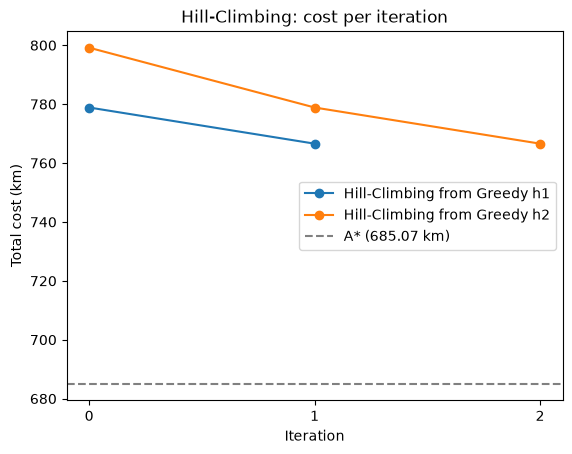

In [10]:
# Cost vs. iteration curves
for name, history in histories.items():
    plt.plot(range(len(history)), history, marker="o", label="Hill-Climbing from " + name)

aStarKm = [r["Total km"] for r in searchResults if r["Algorithm"] == "A*"][0]
plt.axhline(aStarKm, linestyle="--", color="gray", label=f"A* ({aStarKm:.2f} km)")
plt.xlabel("Iteration")
plt.ylabel("Total cost (km)")
plt.title("Hill-Climbing: cost per iteration")
plt.xticks(range(max(len(h) for h in histories.values())))
plt.legend()
plt.show()

---
## 3. CSP (Constraint Satisfaction Problem)

### 3.1 Formulação

Aqui o problema é visto como um **planeamento**: a que veículo vai cada encomenda e a que horas acontece cada serviço. O tempo é discretizado em intervalos de **15 minutos**. Usamos a biblioteca `python-constraint`, como nas aulas.

**Variáveis e domínios**

| Variável | Uma por… | Domínio |
|---|---|---|
| `veh_o` | encomenda | os veículos (1 e 2) |
| `del_o` | encomenda | as horas, de 15 em 15 min, dentro da janela de entrega |
| `pick_i` | item | as horas, de 15 em 15 min, dentro da janela de disponibilidade |

As janelas temporais (disponibilidade nos produtores e prazos de entrega) ficam garantidas logo pelos domínios.

**Restrições rígidas**

1. **Capacidade:** a soma dos pesos das encomendas de cada veículo não passa da sua capacidade.
2. **Fluxo pelo armazém:** cada item só pode ser entregue depois de recolhido, levado ao armazém, descarregado, carregado e transportado até ao cliente: `del_o ≥ pick_i + viagem(produtor→armazém) + serviço + 2 × manuseamento + viagem(armazém→cliente)`.
3. **Tempo máximo no armazém:** entre a chegada ao armazém e a saída para entrega não podem passar mais de 24 h.
4. **Um veículo não está em dois sítios ao mesmo tempo:** duas entregas (ou duas recolhas) do mesmo veículo em locais diferentes têm de estar separadas pelo tempo de viagem entre esses locais mais o tempo de serviço.

**Restrições suaves e heurísticas usadas para as implementar**

As restrições suaves não eliminam soluções: são preferências. O `python-constraint` experimenta os valores **pela ordem em que estão no domínio**, por isso implementamo-las ordenando os domínios. A primeira solução encontrada tende a cumpri-las:

- **cada veículo fica na sua zona:** no `veh_o`, primeiro o veículo da divisão geográfica (secção 0.1);
- **entregar o mais cedo possível:** no `del_o`, as horas por ordem crescente;
- **menos visitas aos produtores:** no `pick_i`, primeiro as horas mais próximas de uma **hora preferida** de cada produtor em cada dia (a hora em que as janelas de todos os seus itens já abriram). Assim, os itens do mesmo produtor tendem a ser recolhidos na mesma visita.

**Algoritmo:** o `RecursiveBacktrackingSolver` da biblioteca, com *forward checking*. Para escolher a próxima variável, usa as heurísticas do grau (primeiro a que entra em mais restrições) e MRV (em caso de empate, a que tem menos valores possíveis).

**Contagem de backtracks:** a biblioteca não os conta. Por isso, criámos uma subclasse (`CountingSolver`) que **não altera a pesquisa**: cada vez que a pesquisa recursiva sai de uma variável sem encontrar solução (ou seja, volta atrás), soma 1.

**Simplificações**

- A restrição 4 compara os serviços **dois a dois**, por isso é um planeamento aproximado: não garante, por si só, que exista uma rota completa que passe por todos os serviços nessas horas. Construir as rotas é o papel da pesquisa informada e local.
- A separação entre uma **recolha e uma entrega** do mesmo veículo ficou de fora. Com ela, o número de restrições sobe de 671 para 1111, e a pesquisa da biblioteca não encontrou solução em vários minutos: descobre demasiado tarde que uma divisão de veículos não tem horários possíveis.

In [11]:
# python-constraint (as in the classes). Imported by name, so it does not collide with model.Problem
from constraint import Problem, RecursiveBacktrackingSolver


class CountingSolver(RecursiveBacktrackingSolver):
    # Same search as the library's RecursiveBacktrackingSolver, but counts the backtracks:
    # every call that ends without finding a solution is a dead end (the search goes back)
    def __init__(self):
        super().__init__(forwardcheck=True)
        self.backtracks = 0

    def recursiveBacktracking(self, solutions, domains, vconstraints, assignments, single):
        before = len(solutions)
        result = super().recursiveBacktracking(solutions, domains, vconstraints, assignments, single)
        if len(solutions) == before:
            self.backtracks += 1
        return result

In [12]:
SLOT = 15   # minutes between two possible times


def minutes(t):
    # Timestamp -> minutes since the start of the horizon
    return int((t - T0).total_seconds() // 60)


def travelMin(a, b):
    return travel(a, b).total_seconds() / 60


SERVICE_MIN = SERVICE.total_seconds() / 60
HANDLING_MIN = HANDLING.total_seconds() / 60
MAX_DWELL_MIN = checkData["max_warehouse"].total_seconds() / 60


def slots(start, end):
    # Times (in minutes) every 15 minutes inside a window
    first = minutes(start)
    first = first + (-first) % SLOT
    return list(range(first, minutes(end) + 1, SLOT))


orders = sorted({r.orderId for r in problem.requests})
itemsOfOrder = {o: [r.orderItemId for r in problem.requests if r.orderId == o] for o in orders}
weightOfOrder = {o: sum(requestById[i].weightKg for i in itemsOfOrder[o]) for o in orders}
stopOfOrder = {o: requestById[itemsOfOrder[o][0]].deliveryStopId for o in orders}
capacity = {v.vehicleId: v.capacityKg for v in problem.vehicles}

# Preferred pickup time for each (producer, day): when the windows of all its items are already open
preferred = {}
for r in problem.requests:
    key = (r.pickupStopId, r.availabilityStart.date())
    preferred[key] = max(preferred.get(key, 0), minutes(r.availabilityStart))

In [13]:
def buildCSP(softOrder=True):
    # Creates the CSP; softOrder=False keeps the domains in plain order (to compare the heuristics)
    solver = CountingSolver()
    csp = Problem(solver)

    # ---------- variables and domains (the order of the values implements the soft constraints) ----------
    for o in orders:
        first = requestById[itemsOfOrder[o][0]]
        vehicles = list(capacity)
        if softOrder:
            # Soft: each vehicle stays in its area -> vehicle of the geographic division first
            vehicles.sort(key=lambda v: v != assignment[o])
        csp.addVariable("veh_" + str(o), vehicles)
        # Soft: deliver as early as possible -> earliest times first
        csp.addVariable("del_" + str(o), slots(first.deliveryStart, first.deliveryEnd))

    for r in problem.requests:
        values = slots(r.availabilityStart, r.availabilityEnd)
        if softOrder:
            # Soft: fewer visits -> times closest to the preferred time of the producer first
            p = preferred[(r.pickupStopId, r.availabilityStart.date())]
            values.sort(key=lambda t: (abs(t - p), t))
        csp.addVariable("pick_" + str(r.orderItemId), values)

    # ---------- 1) capacity ----------
    def capacityOk(*vehiclesOfOrders):
        load = {v: 0 for v in capacity}
        for o, v in zip(orders, vehiclesOfOrders):
            load[v] += weightOfOrder[o]
        return all(load[v] <= capacity[v] for v in capacity)

    csp.addConstraint(capacityOk, ["veh_" + str(o) for o in orders])

    # ---------- 2) flow through the warehouse and 3) max time in the warehouse ----------
    for r in problem.requests:
        pickVar, delVar = "pick_" + str(r.orderItemId), "del_" + str(r.orderId)
        chain = (travelMin(r.pickupStopId, DEPOT) + SERVICE_MIN + 2 * HANDLING_MIN
                 + travelMin(DEPOT, r.deliveryStopId))
        arriveWarehouse = SERVICE_MIN + travelMin(r.pickupStopId, DEPOT) + HANDLING_MIN
        leaveWarehouse = travelMin(DEPOT, r.deliveryStopId) + HANDLING_MIN

        csp.addConstraint(lambda pick, deliver, chain=chain: deliver >= pick + chain, [pickVar, delVar])
        csp.addConstraint(lambda pick, deliver, aw=arriveWarehouse, lw=leaveWarehouse:
                          (deliver - lw) - (pick + aw) <= MAX_DWELL_MIN, [pickVar, delVar])

    # ---------- 4) a vehicle is not in two places at the same time ----------
    def separated(v1, v2, t1, t2, gap):
        # Different vehicles, or times separated by the travel time between the two places
        return v1 != v2 or abs(t1 - t2) >= gap

    # Deliveries of two orders
    for x in range(len(orders)):
        for y in range(x + 1, len(orders)):
            o1, o2 = orders[x], orders[y]
            if stopOfOrder[o1] == stopOfOrder[o2]:
                continue
            gap = travelMin(stopOfOrder[o1], stopOfOrder[o2]) + SERVICE_MIN
            csp.addConstraint(lambda v1, v2, t1, t2, gap=gap: separated(v1, v2, t1, t2, gap),
                              ["veh_" + str(o1), "veh_" + str(o2), "del_" + str(o1), "del_" + str(o2)])

    # Pickups of two items at different producers
    for x in range(len(problem.requests)):
        for y in range(x + 1, len(problem.requests)):
            r1, r2 = problem.requests[x], problem.requests[y]
            if r1.pickupStopId == r2.pickupStopId:
                continue
            gap = travelMin(r1.pickupStopId, r2.pickupStopId) + SERVICE_MIN
            csp.addConstraint(lambda v1, v2, t1, t2, gap=gap: separated(v1, v2, t1, t2, gap),
                              ["veh_" + str(r1.orderId), "veh_" + str(r2.orderId),
                               "pick_" + str(r1.orderItemId), "pick_" + str(r2.orderItemId)])

    return csp, solver

### 3.2 Resultado: atribuição viável e número de backtracks

In [14]:
csp, solver = buildCSP(softOrder=True)
print("Variables:", len(csp._variables), "| Constraints:", len(csp._constraints))

start = time.perf_counter()
solution = csp.getSolution()
cspTime = time.perf_counter() - start
backtracks = solver.backtracks

print(f"Solution found: {solution is not None} | backtracks: {backtracks} | time: {cspTime:.4f} s")


def clock(m):
    return f"{T0 + pd.Timedelta(minutes=m):%d/%m %H:%M}"


rows = []
for o in orders:
    rows.append({"Order": o, "Vehicle": solution["veh_" + str(o)], "Stop": stopName[stopOfOrder[o]],
                 "Delivery": clock(solution["del_" + str(o)]), "Weight (kg)": round(weightOfOrder[o], 1),
                 "Pickups": ", ".join(clock(solution["pick_" + str(i)])[6:] for i in itemsOfOrder[o])})
pd.DataFrame(rows)

Variables: 64 | Constraints: 671
Solution found: True | backtracks: 12 | time: 0.0192 s


,Order,Vehicle,Stop,Delivery,Weight (kg),Pickups
0,1,2,Casa 3,31/10 12:30,22.0,"09:45, 09:00, 07:45, 07:45"
1,2,1,Casa 4,31/10 07:15,6.8,"09:30, 08:00"
2,3,1,Casa 2,31/10 12:15,21.6,"09:45, 07:45, 07:45, 09:00"
3,4,2,Casa 3,30/10 12:00,26.3,"08:00, 08:45, 09:30"
4,5,2,Loja 1,31/10 11:45,9.3,"07:45, 09:45"
5,6,2,Casa 3,31/10 12:30,16.7,"09:45, 07:45"
6,7,2,Loja 5,31/10 12:15,33.5,"09:45, 09:00, 09:00, 09:00"
7,8,1,Casa 2,31/10 09:30,18.8,"08:00, 10:15, 08:00"
8,9,2,Loja 5,31/10 08:15,36.7,"09:30, 08:00, 08:45, 08:45, 08:00"
9,10,1,Casa 4,30/10 13:15,9.2,"08:45, 09:30"


In [15]:
# How well were the soft constraints met?
for v in capacity:
    kg = sum(weightOfOrder[o] for o in orders if solution["veh_" + str(o)] == v)
    print(f"Vehicle {v}: {kg:.1f} kg of {capacity[v]:.0f} kg")

sameArea = sum(1 for o in orders if solution["veh_" + str(o)] == assignment[o])
print(f"Orders in the vehicle of their area: {sameArea} of {len(orders)}")

# Number of producer visits = different (vehicle, producer, time) combinations
visits = {(solution["veh_" + str(r.orderId)], r.pickupStopId, solution["pick_" + str(r.orderItemId)])
          for r in problem.requests}
print(f"Producer visits: {len(visits)} (for {len(problem.requests)} items)")

Vehicle 1: 107.5 kg of 150 kg
Vehicle 2: 162.5 kg of 200 kg
Orders in the vehicle of their area: 12 of 12
Producer visits: 13 (for 40 items)


### 3.3 Efeito das heurísticas das restrições suaves

Para medir o efeito da ordem dos valores, resolvemos o mesmo CSP com os domínios pela ordem simples (veículos 1, 2; horas por ordem crescente) e comparamos o número de backtracks e de visitas aos produtores.

In [16]:
cspPlain, solverPlain = buildCSP(softOrder=False)
start = time.perf_counter()
solutionPlain = cspPlain.getSolution()
cspPlainTime = time.perf_counter() - start

visitsPlain = {(solutionPlain["veh_" + str(r.orderId)], r.pickupStopId, solutionPlain["pick_" + str(r.orderItemId)])
               for r in problem.requests}

pd.DataFrame([
    {"Value order": "with heuristics (soft constraints)", "Backtracks": backtracks,
     "Producer visits": len(visits), "Time (s)": round(cspTime, 4)},
    {"Value order": "plain", "Backtracks": solverPlain.backtracks,
     "Producer visits": len(visitsPlain), "Time (s)": round(cspPlainTime, 4)},
])

,Value order,Backtracks,Producer visits,Time (s)
0,with heuristics (soft constraints),12,13,0.0192
1,plain,117,20,0.0276


---
## 4. Análise de resultados

### 4.1 Tabela comparativa

In [17]:
summary = []
for r in searchResults:
    summary.append({"Method": r["Algorithm"] + " (" + r["Heuristic"] + ")", "Total km": r["Total km"],
                    "Expanded nodes / iterations / backtracks": r["Expanded nodes"], "Time (s)": r["Time (s)"]})
for r in localResults:
    summary.append({"Method": "Hill-Climbing on " + r["Initial solution"], "Total km": r["Final cost (km)"],
                    "Expanded nodes / iterations / backtracks": r["Iterations"], "Time (s)": r["Time (s)"]})
summary.append({"Method": "CSP (python-constraint, forward checking)", "Total km": None,
                "Expanded nodes / iterations / backtracks": backtracks, "Time (s)": round(cspTime, 4)})
pd.DataFrame(summary)

,Method,Total km,Expanded nodes / iterations / backtracks,Time (s)
0,Greedy (h1),778.86,855,0.1525
1,Greedy (h2),799.17,548,0.0651
2,A* (h1),685.07,1057,0.0986
3,A* (h2),685.07,806,0.1082
4,Hill-Climbing on Greedy h1,766.58,1,0.1845
5,Hill-Climbing on Greedy h2,766.58,2,0.2676
6,"CSP (python-constraint, forward checking)",NaN,12,0.0192


### 4.2 Análise crítica

- **Melhor solução:** o **A\*** encontra a rota mais curta (685,07 km no total), com as duas heurísticas. Com as heurísticas admissíveis, a solução é ótima **para a formulação usada** (divisão das encomendas pelos veículos e ações definidas na secção 1.1). Todas as rotas passam no verificador sem erros.
- **Heurísticas:** com a heurística 2, o A\* chega ao mesmo custo expandindo **menos nós** (806 contra 1057). É o efeito esperado de uma heurística mais informada, que domina a outra.
- **Greedy vs. A\*:** o Greedy é rápido, mas não é ótimo: as suas soluções custam 778,86 km (h1) e 799,17 km (h2), cerca de 14 a 17 % acima do A\*. Também não expande necessariamente menos nós (com h1 expandiu 855). Ao olhar só para `h`, ignora os km já percorridos.
- **Hill-Climbing:** melhora as soluções do Greedy (de 799,17 e 778,86 para 766,58 km) em 1 a 2 iterações, mas pára num **ótimo local** ainda longe do A\*. A vizinhança (mudar uma paragem de posição) é pequena, e muitos vizinhos ficam inviáveis por causa das janelas temporais.
- **CSP:** o `python-constraint` encontra uma atribuição viável (veículo e horários de todas as encomendas) com 12 *backtracks*, em milésimos de segundo. As heurísticas das restrições suaves fazem diferença: com os domínios pela ordem simples, são precisos 117 *backtracks*, e a solução obriga a 20 visitas aos produtores em vez de 13. Com a separação entre recolhas e entregas incluída, a pesquisa da biblioteca não terminou em vários minutos, porque escolhe primeiro os veículos de todas as encomendas e só muito mais abaixo na árvore descobre que uma divisão não tem horários possíveis.
- **Tempos:** todos os métodos correm em frações de segundo no dataset *tiny*. Nesta escala, a diferença entre os algoritmos está na qualidade da solução e no número de nós, não no tempo.
- **Capacidade:** como já se tinha visto na EDA, a capacidade não é o limite principal; o que restringe as rotas são as **janelas temporais** e as distâncias entre produtores.

### 4.3 Melhorias futuras

- **Pesquisa conjunta dos dois veículos:** a divisão geográfica das encomendas é fixa; deixar o algoritmo decidir o veículo de cada encomenda pode encontrar soluções melhores.
- **Armazém como ponto de transferência:** permitir que um veículo recolha e outro entregue, e modelar o tempo de permanência no armazém (hoje os itens são carregados logo após a descarga).
- **Pesquisa local mais forte:** vizinhanças maiores (trocar encomendas entre veículos, 2-opt) e métodos que fogem de ótimos locais, como o Simulated Annealing ou reinícios aleatórios.
- **CSP mais completo:** incluir a separação entre recolhas e entregas (com uma ordem de variáveis que descubra mais cedo as divisões impossíveis), restrições de rota completas e a minimização dos km como objetivo.
- **Dataset maior:** testar com o dataset *small* e medir como o número de nós e o tempo crescem.

---
## 5. Conclusão

O agente encontra rotas viáveis de recolha e entrega para os dois veículos, respeitando as janelas de disponibilidade e de entrega, a capacidade dos veículos e a passagem obrigatória pelo armazém. As três famílias de algoritmos mostram compromissos diferentes: o A\* dá a melhor solução e, com uma heurística mais informada, explora menos estados; o Greedy é uma boa solução inicial, mas não é ótima; o Hill-Climbing melhora-a rapidamente, mas fica preso em ótimos locais; e o CSP é a abordagem natural para lidar com as restrições temporais e de capacidade, e a ordem dos valores mostrou ser uma forma simples e eficaz de implementar as restrições suaves.

Quanto ao processo, separar o modelo (`model.py`) dos algoritmos permitiu reaproveitar a mesma função de custo e o mesmo verificador em todos os métodos, e comparar resultados de forma justa. As ferramentas usadas foram Python, `pandas` para os dados, `heapq` para as filas de prioridade, `python-constraint` para o CSP e `matplotlib` para os gráficos, num Jupyter Notebook.